# Water Demand Prediction using Machine Learning

Predict the **total annual water demand** of each Indian state (in BCM = Billion Cubic Metres) using rainfall, groundwater and urban census data.

## Step 1: Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

## Step 2: Load and clean the data


In [ ]:
GROUNDWATER_FILE = 'Groundwater_data.csv'
RAIN_FILE = 'Rain_data.csv'
CENSUS_FILE = 'census_data.csv'

### 2.1 Groundwater data (State x Year)


In [ ]:
groundwater = pd.read_csv(GROUNDWATER_FILE)

new_names = []
for name in groundwater.columns:
    short_name = name.split(' (UOM')[0]
    new_names.append(short_name)
groundwater.columns = new_names


groundwater = groundwater.rename(columns={
    'Groundwater Recharge In Monsoon Season By Rainfall': 'Recharge_Monsoon_Rain',
    'Groundwater Recharge In Monsoon Season By Other Sources': 'Recharge_Monsoon_Other',
    'Groundwater Recharge In Non Monsoon Season By Rainfall': 'Recharge_NonMonsoon_Rain',
    'Groundwater Recharge In Non Monsoon Season By Other Sources': 'Recharge_NonMonsoon_Other',
    'Total Natural Discharge Of Groundwater Resources': 'Natural_Discharge',
    'Annual Extractable Ground Water Resource': 'Extractable_Resource',
    'Current Annual Groundwater Extraction For Irrigation': 'Irrigation_Use',
    'Current Annual Groundwater Extraction For Industrial Use': 'Industrial_Use',
    'Current Annual Groundwater Extraction For Domestic Use': 'Domestic_Use'})


groundwater['Year'] = groundwater['Year'].str[-4:].astype(int)

# Make state names lowercase so they match in all three files
groundwater['State'] = groundwater['State'].str.lower().str.strip()

# TARGET: total water demand = irrigation + industrial + domestic
groundwater['Total_Demand'] = (groundwater['Irrigation_Use'] +
                               groundwater['Industrial_Use'] +
                               groundwater['Domestic_Use'])

groundwater = groundwater[['State', 'Year', 'Recharge_Monsoon_Rain', 'Recharge_Monsoon_Other',
                           'Recharge_NonMonsoon_Rain', 'Recharge_NonMonsoon_Other',
                           'Natural_Discharge', 'Extractable_Resource', 'Total_Demand']]

print('Shape:', groundwater.shape)
print('Years available:', sorted(groundwater['Year'].unique().tolist()))
groundwater.head()

Shape: (144, 9)
Years available: [2020, 2022, 2023, 2024]


,State,Year,Recharge_Monsoon_Rain,Recharge_Monsoon_Other,Recharge_NonMonsoon_Rain,Recharge_NonMonsoon_Other,Natural_Discharge,Extractable_Resource,Total_Demand
0,andaman and nicobar islands,2024,0.20,0.00,0.17,0.00,0.04,0.34,0.01
1,andhra pradesh,2024,9.00,10.79,0.82,7.18,1.39,26.41,7.88
2,arunachal pradesh,2024,2.16,0.27,1.11,0.34,0.42,3.46,0.02
3,assam,2024,19.45,0.67,6.53,0.56,6.32,20.89,2.63
4,bihar,2024,19.54,8.05,1.14,5.42,3.19,30.95,14.09


### 2.2 Rainfall data (District x Day -> State x Year)

In [ ]:
rain = pd.read_csv(RAIN_FILE,
                   usecols=['State', 'Year',
                            'Daily Actual (UOM:mm(Millimeter)), Scaling Factor:1',
                            'Daily Normal (UOM:mm(Millimeter)), Scaling Factor:1'],
                   engine='python',
                   on_bad_lines='skip')

rain.columns = ['State', 'Year', 'Daily_Actual', 'Daily_Normal']


rain['Year'] = rain['Year'].str[-4:].astype(int)
rain['State'] = rain['State'].str.lower().str.strip()

rain['Rainy_Day'] = (rain['Daily_Actual'] > 2.5).astype(int)

# Group by State and Year, then calculate the average of each column
rain_summary = rain.groupby(['State', 'Year']).agg(
    AvgRain=('Daily_Actual', 'mean'),        # average rainfall per day (mm)
    AvgNormal=('Daily_Normal', 'mean'),      # average normal rainfall per day (mm)
    RainyShare=('Rainy_Day', 'mean')         # fraction of days that were rainy
).reset_index()

rain_summary['RainDeparture'] = (rain_summary['AvgRain'] - rain_summary['AvgNormal']) / rain_summary['AvgNormal'] * 100

print('Original rainfall rows:', len(rain))
print('After summarising:', rain_summary.shape)
rain_summary.head()

Original rainfall rows: 1325853
After summarising: (216, 6)


,State,Year,AvgRain,AvgNormal,RainyShare,RainDeparture
0,andaman and nicobar islands,2021,12.063970,10.943689,0.139459,10.236772
1,andaman and nicobar islands,2022,10.433333,9.366036,0.142068,11.395405
2,andaman and nicobar islands,2023,11.201120,9.386114,0.130972,19.337135
3,andaman and nicobar islands,2024,8.901247,8.764266,0.448753,1.562944
4,andaman and nicobar islands,2025,8.797709,7.985281,0.452463,10.174075


### 2.3 Census data (Town level -> State level)

In [ ]:
census = pd.read_csv(CENSUS_FILE)

new_names = []
for name in census.columns:
    short_name = name.split(' (UOM')[0]
    new_names.append(short_name)
census.columns = new_names

# Clean the state names
census['State'] = census['State'].str.lower().str.strip()

census.loc[census['Max Temperature'] > 60, 'Max Temperature'] = np.nan
census.loc[census['Rainfall'] > 10000, 'Rainfall'] = np.nan

# Combine all towns of a state into one row
census_summary = census.groupby('State').agg(
    Towns=('Ulb_Rlb_Village', 'count'),                          # number of towns
    UrbanPop=('Urban Population', 'sum'),                        # total urban population
    UrbanHH=('Urban Households', 'sum'),                         # total urban households
    TownArea=('Area', 'sum'),                                    # total town area (sq km)
    Density=('Population Density-Census 2011', 'median'),        # typical population density
    ElecDomestic=('Number Of Electricity-Domestic Connection', 'sum'),    # home electricity connections
    ElecIndustrial=('Number Of Electricity-Industrial Connection', 'sum'),# industry electricity connections
    WaterSourceCap=('Capacity Source-1', 'sum'),                 # capacity of main water source (kilolitres)
    Flush=('Number Of Flush Or Pour Flush Latrine', 'sum'),      # flush latrines (water use indicator)
    Rain2011=('Rainfall', 'median'),                             # typical yearly rainfall in 2011 (mm)
    MaxTemp=('Max Temperature', 'median')                        # typical maximum temperature
).reset_index()

print('Census summary shape:', census_summary.shape)
census_summary.head()

Census summary shape: (36, 12)


,State,Towns,UrbanPop,UrbanHH,TownArea,Density,ElecDomestic,ElecIndustrial,WaterSourceCap,Flush,Rain2011,MaxTemp
0,andaman and nicobar islands,5,143488.0,36021.0,37.994,2230.0,40479.0,785.0,7.280860e+05,23304.0,3180.00,33.0
1,andhra pradesh,195,14610410.0,3653618.0,4119.340,2621.0,3929143.0,48433.0,1.521973e+06,3163528.0,951.42,42.0
2,arunachal pradesh,27,317369.0,70367.0,0.000,0.0,66809.0,187.0,1.312524e+07,69146.0,1985.00,32.7
3,assam,214,4398542.0,985594.0,1259.880,2897.3,833241.0,16186.0,3.889492e+05,689689.0,1816.00,37.0
4,bihar,199,11758016.0,2050625.0,2324.720,4220.0,970855.0,37766.0,6.355562e+05,651648.0,1051.00,43.0


## Step 3: Combine all three tables

In [ ]:
# Join groundwater + rainfall on State and Year
data = groundwater.merge(rain_summary, on=['State', 'Year'], how='inner')

# Join census data on State
data = data.merge(census_summary, on='State', how='left')

print('Final table shape:', data.shape)
print('Years used:', sorted(data['Year'].unique().tolist()))
print('States:', data['State'].nunique())
print()
print('Missing values:')
print(data.isnull().sum()[data.isnull().sum() > 0])

Final table shape: (72, 24)
Years used: [2023, 2024]
States: 36

Missing values:
Density    4
dtype: int64


In [ ]:
# Fill the few missing values with the median of that column
for column in data.columns:
    if data[column].isnull().sum() > 0:
        data[column] = data[column].fillna(data[column].median())

print('Total missing values left:', data.isnull().sum().sum())
data.head()

Total missing values left: 0


,State,Year,Recharge_Monsoon_Rain,Recharge_Monsoon_Other,Recharge_NonMonsoon_Rain,Recharge_NonMonsoon_Other,Natural_Discharge,Extractable_Resource,Total_Demand,AvgRain,...,UrbanPop,UrbanHH,TownArea,Density,ElecDomestic,ElecIndustrial,WaterSourceCap,Flush,Rain2011,MaxTemp
0,andaman and nicobar islands,2024,0.20,0.00,0.17,0.00,0.04,0.34,0.01,8.901247,...,143488.0,36021.0,37.994,2230.0,40479.0,785.0,7.280860e+05,23304.0,3180.00,33.0
1,andhra pradesh,2024,9.00,10.79,0.82,7.18,1.39,26.41,7.88,3.636720,...,14610410.0,3653618.0,4119.340,2621.0,3929143.0,48433.0,1.521973e+06,3163528.0,951.42,42.0
2,arunachal pradesh,2024,2.16,0.27,1.11,0.34,0.42,3.46,0.02,7.527640,...,317369.0,70367.0,0.000,0.0,66809.0,187.0,1.312524e+07,69146.0,1985.00,32.7
3,assam,2024,19.45,0.67,6.53,0.56,6.32,20.89,2.63,6.486430,...,4398542.0,985594.0,1259.880,2897.3,833241.0,16186.0,3.889492e+05,689689.0,1816.00,37.0
4,bihar,2024,19.54,8.05,1.14,5.42,3.19,30.95,14.09,3.355226,...,11758016.0,2050625.0,2324.720,4220.0,970855.0,37766.0,6.355562e+05,651648.0,1051.00,43.0


## Step 4: Explore the data

In [ ]:
print(data['Total_Demand'].describe())

count    72.000000
mean      6.763967
std       9.868022
min       0.000000
25%       0.055225
50%       1.440000
75%      11.617500
max      46.760000
Name: Total_Demand, dtype: float64


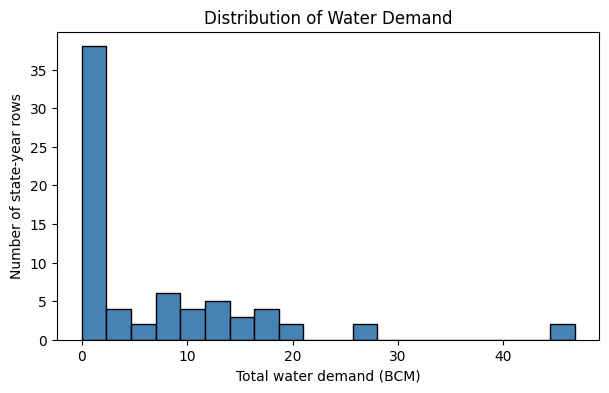

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(data['Total_Demand'], bins=20, color='steelblue', edgecolor='black')
plt.xlabel('Total water demand (BCM)')
plt.ylabel('Number of state-year rows')
plt.title('Distribution of Water Demand')
plt.show()

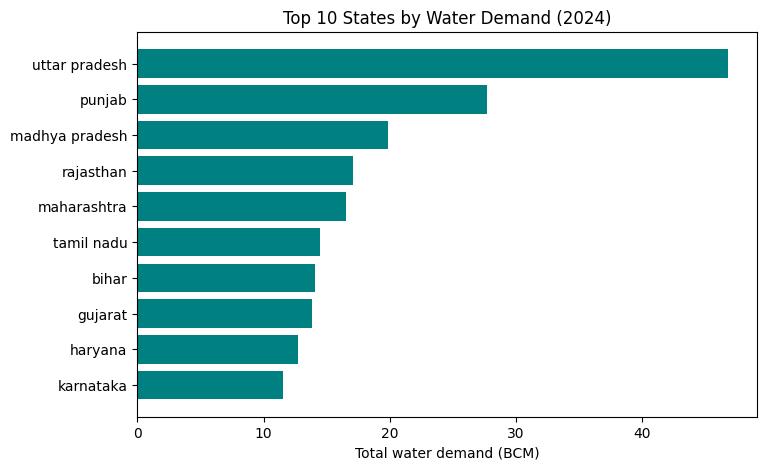

In [ ]:
#Top 10 states by water demand in 2024
latest = data[data['Year'] == 2024]                                   # keep only year 2024
top10 = latest.sort_values('Total_Demand', ascending=False).head(10)  # 10 biggest values
top10 = top10.sort_values('Total_Demand')                             # sort small to big for the bar chart

plt.figure(figsize=(8, 5))
plt.barh(top10['State'], top10['Total_Demand'], color='teal')
plt.xlabel('Total water demand (BCM)')
plt.title('Top 10 States by Water Demand (2024)')
plt.show()

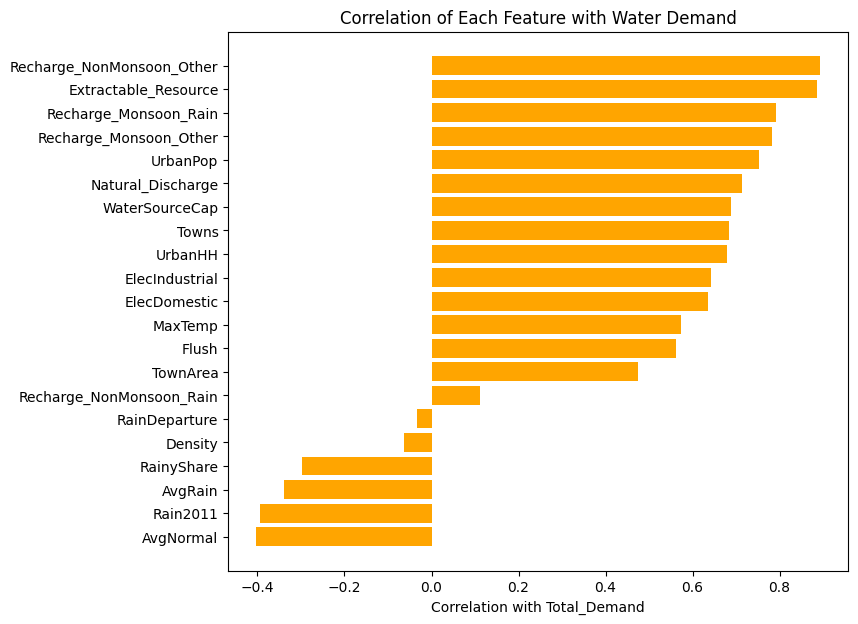

In [ ]:
feature_list = ['Recharge_Monsoon_Rain', 'Recharge_Monsoon_Other',
                'Recharge_NonMonsoon_Rain', 'Recharge_NonMonsoon_Other',
                'Natural_Discharge', 'Extractable_Resource',
                'AvgRain', 'AvgNormal', 'RainyShare', 'RainDeparture',
                'Towns', 'UrbanPop', 'UrbanHH', 'TownArea', 'Density',
                'ElecDomestic', 'ElecIndustrial', 'WaterSourceCap', 'Flush',
                'Rain2011', 'MaxTemp']

# Calculate the correlation of each feature with the target
correlations = data[feature_list].corrwith(data['Total_Demand'])
correlations = correlations.sort_values()

plt.figure(figsize=(8, 7))
plt.barh(correlations.index, correlations.values, color='orange')
plt.xlabel('Correlation with Total_Demand')
plt.title('Correlation of Each Feature with Water Demand')
plt.show()

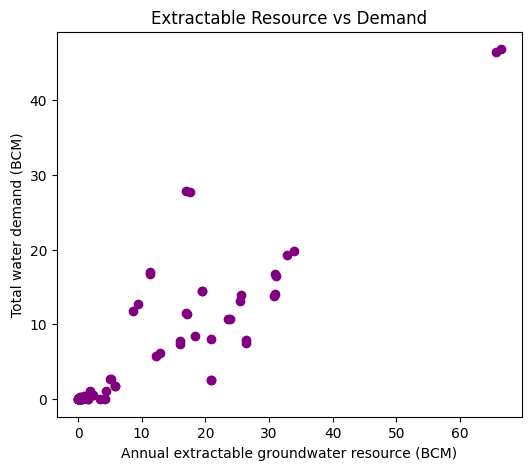

In [ ]:
#Extractable groundwater resource vs water demand
plt.figure(figsize=(6, 5))
plt.scatter(data['Extractable_Resource'], data['Total_Demand'], color='purple')
plt.xlabel('Annual extractable groundwater resource (BCM)')
plt.ylabel('Total water demand (BCM)')
plt.title('Extractable Resource vs Demand')
plt.show()

## Step 5: Prepare data for the models

In [ ]:
X = data[feature_list]
y = data['Total_Demand']

# Split into training (80%) and testing (20%).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training rows:', len(X_train))
print('Testing rows :', len(X_test))

Training rows: 57
Testing rows : 15


## Step 6: Train and compare the models

In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, random_state=42)
}

results = []

for model_name in models:
    model = models[model_name]
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    r2 = r2_score(y_test, predictions)                           # R2 score
    mae = mean_absolute_error(y_test, predictions)               # average error
    rmse = np.sqrt(mean_squared_error(y_test, predictions))      # root mean squared error

    # 5-fold cross validation: train/test 5 times on different parts of the data
    cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')
    cv_r2 = cv_scores.mean()                                     # average of the 5 scores

    results.append([model_name, r2, mae, rmse, cv_r2])

# Show the results as a table
results_table = pd.DataFrame(results, columns=['Model', 'R2 (test)', 'MAE', 'RMSE', 'R2 (5-fold CV)'])
results_table = results_table.round(3)
results_table

,Model,R2 (test),MAE,RMSE,R2 (5-fold CV)
0,Linear Regression,0.762,2.800,4.355,0.499
1,Decision Tree,0.956,1.291,1.878,0.829
2,Random Forest,0.896,1.808,2.872,0.878
3,Gradient Boosting,0.949,1.174,2.012,0.964


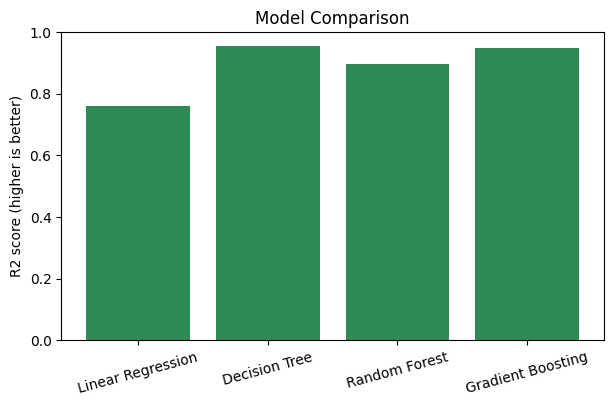

In [ ]:
#Compare the R2 score of all models
plt.figure(figsize=(7, 4))
plt.bar(results_table['Model'], results_table['R2 (test)'], color='seagreen')
plt.ylabel('R2 score (higher is better)')
plt.title('Model Comparison')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

Best model: Decision Tree


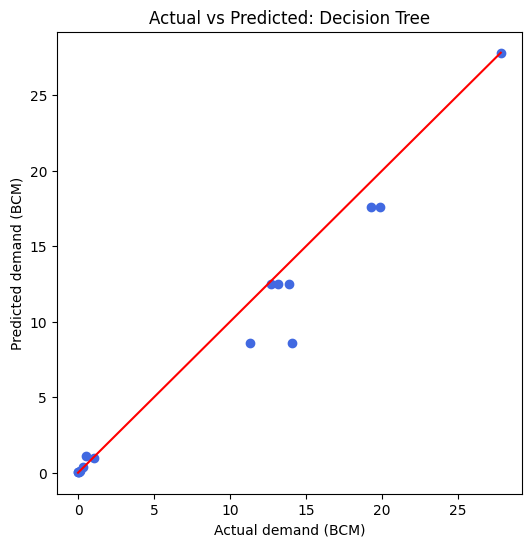

In [ ]:
# Find the model with the highest R2 score on the test data
best_row = results_table.sort_values('R2 (test)', ascending=False).iloc[0]
best_name = best_row['Model']
print('Best model:', best_name)

best_model = models[best_name]
best_predictions = best_model.predict(X_test)   # predict on test data

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, color='royalblue')
# Red line = perfect predictions (predicted equals actual)
max_value = max(y_test.max(), best_predictions.max())
plt.plot([0, max_value], [0, max_value], color='red')
plt.xlabel('Actual demand (BCM)')
plt.ylabel('Predicted demand (BCM)')
plt.title('Actual vs Predicted: ' + best_name)
plt.show()

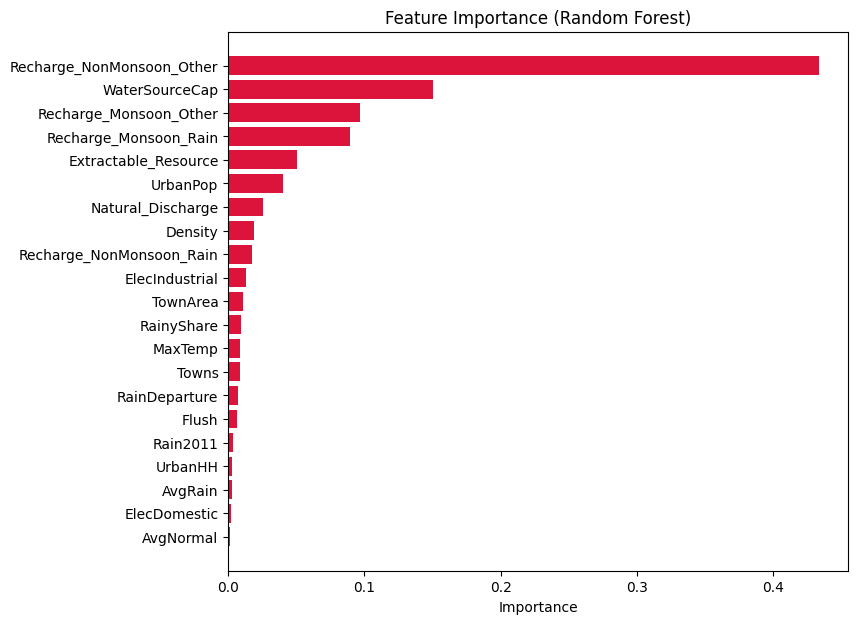

Top 5 most important features:
Recharge_NonMonsoon_Other    0.433
WaterSourceCap               0.150
Recharge_Monsoon_Other       0.096
Recharge_Monsoon_Rain        0.089
Extractable_Resource         0.051
dtype: float64


In [ ]:
# Train a Random Forest
forest = RandomForestRegressor(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)

# Put importance values in a table and sort them
importance = pd.Series(forest.feature_importances_, index=feature_list)
importance = importance.sort_values()

plt.figure(figsize=(8, 7))
plt.barh(importance.index, importance.values, color='crimson')
plt.xlabel('Importance')
plt.title('Feature Importance (Random Forest)')
plt.show()

print('Top 5 most important features:')
print(importance.sort_values(ascending=False).head(5).round(3))

### Investigating Feature Relevance: Correlation vs. Mutual Information
Let's evaluate if these top features are genuinely informative by comparing linear correlation and Non-linear Mutual Information (MI) scores. MI measures how much information the feature shares with our target (`Total_Demand`).

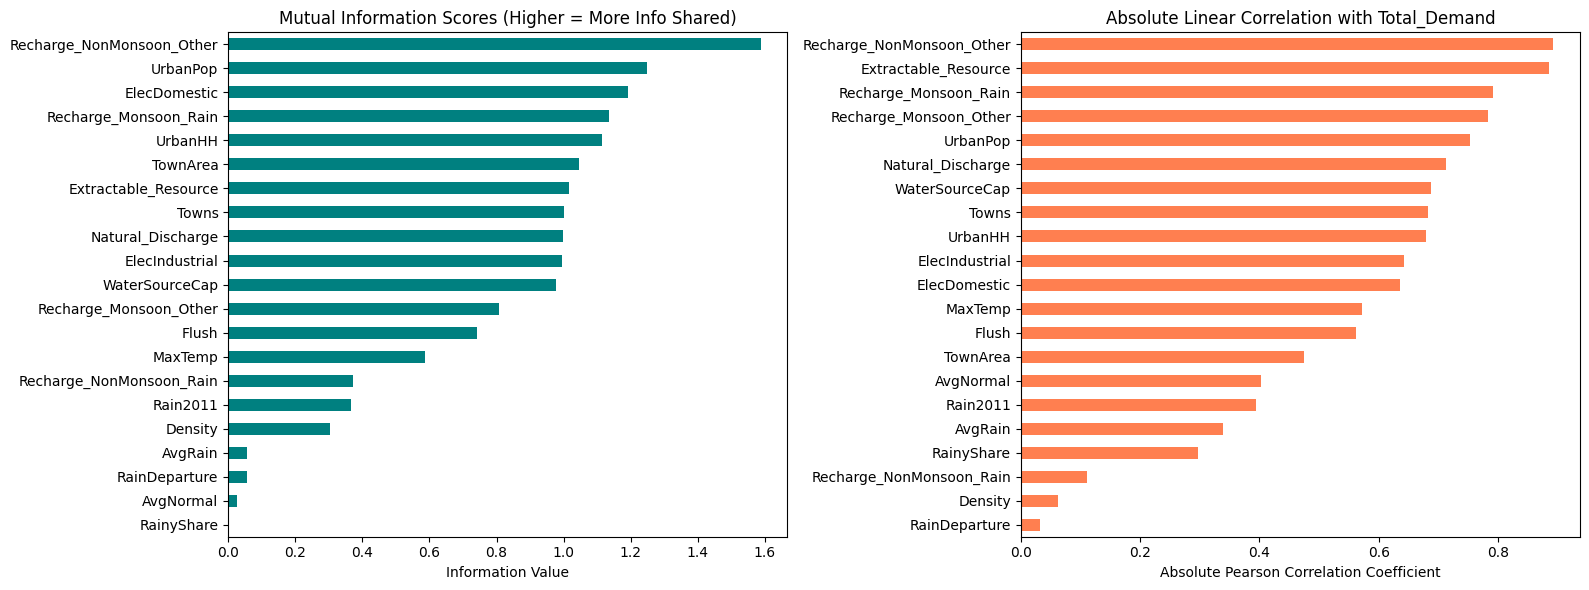

--- Top 5 Features by Mutual Information (Captures Non-linear relations) ---
Recharge_NonMonsoon_Other    1.588062
UrbanPop                     1.248310
ElecDomestic                 1.192178
Recharge_Monsoon_Rain        1.136257
UrbanHH                      1.113531
dtype: float64

--- Top 5 Features by Absolute Pearson Correlation (Linear) ---
Recharge_NonMonsoon_Other    0.892922
Extractable_Resource         0.885769
Recharge_Monsoon_Rain        0.791376
Recharge_Monsoon_Other       0.783067
UrbanPop                     0.752604
dtype: float64


In [ ]:
from sklearn.feature_selection import mutual_info_regression
import pandas as pd
import matplotlib.pyplot as plt

# Calculate Mutual Information Scores
mi_scores = mutual_info_regression(X, y, random_state=42)
mi_series = pd.Series(mi_scores, index=feature_list).sort_values(ascending=True)

# Get absolute Pearson correlation values
abs_corr = X.corrwith(y).abs().sort_values(ascending=True)

# Plot both side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot MI
mi_series.plot(kind='barh', ax=ax1, color='teal')
ax1.set_title('Mutual Information Scores (Higher = More Info Shared)')
ax1.set_xlabel('Information Value')

# Plot Absolute Correlation
abs_corr.plot(kind='barh', ax=ax2, color='coral')
ax2.set_title('Absolute Linear Correlation with Total_Demand')
ax2.set_xlabel('Absolute Pearson Correlation Coefficient')

plt.tight_layout()
plt.show()

# Display top 5 in both
print("--- Top 5 Features by Mutual Information (Captures Non-linear relations) ---")
print(mi_series.sort_values(ascending=False).head(5))
print("\n--- Top 5 Features by Absolute Pearson Correlation (Linear) ---")
print(abs_corr.sort_values(ascending=False).head(5))

## Step 8: Predict the latest year (2024) from past years

In [ ]:
# Training data = years before 2024, testing data = year 2024
train_rows = data[data['Year'] < 2024]
test_rows = data[data['Year'] == 2024]

X_train_t = train_rows[feature_list]
y_train_t = train_rows['Total_Demand']
X_test_t = test_rows[feature_list]
y_test_t = test_rows['Total_Demand']

print('Training rows (2022-2023):', len(train_rows))
print('Testing rows  (2024)     :', len(test_rows))

# Train every model on the past years and test on 2024
time_results = []
for model_name in models:
    model = models[model_name]
    model.fit(X_train_t, y_train_t)
    predictions = model.predict(X_test_t)

    r2 = r2_score(y_test_t, predictions)
    mae = mean_absolute_error(y_test_t, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_t, predictions))
    time_results.append([model_name, r2, mae, rmse])

time_table = pd.DataFrame(time_results, columns=['Model', 'R2 (2024)', 'MAE', 'RMSE']).round(3)
time_table

Training rows (2022-2023): 36
Testing rows  (2024)     : 36


,Model,R2 (2024),MAE,RMSE
0,Linear Regression,-1.713,4.840,16.226
1,Decision Tree,0.894,1.416,3.200
2,Random Forest,0.910,1.572,2.949
3,Gradient Boosting,0.977,0.518,1.483


## Step 9:predicting states the model has never seen


In [ ]:
# Split the data 5 times, keeping each state's rows together
group_cv = GroupKFold(n_splits=5)
state_groups = data['State']
strict_results = []
for model_name in models:
    model = models[model_name]
    # R2 score for each of the 5 splits (every split tests on states not used in training)
    scores = cross_val_score(model, X, y, cv=group_cv, groups=state_groups, scoring='r2')
    strict_results.append([model_name, scores.mean(), scores.min(), scores.max()])

strict_table = pd.DataFrame(strict_results, columns=['Model', 'Mean R2', 'Worst split', 'Best split']).round(3)
strict_table

,Model,Mean R2,Worst split,Best split
0,Linear Regression,-4.767,-23.938,0.543
1,Decision Tree,-3.953,-20.799,0.857
2,Random Forest,0.077,-1.079,0.801
3,Gradient Boosting,-0.403,-3.299,0.818


## Step 10: Predictions for every state in 2024 and saving the results

In [ ]:
# We use Gradient Boosting as the final model.
# It had the best R2 in Step 6 (and in cross-validation) and was almost tied for best in Step 8.
final_model = models['Gradient Boosting']
final_model.fit(X_train_t, y_train_t)               # train on 2022-2023
final_predictions = final_model.predict(X_test_t)   # predict 2024

# Put actual and predicted values side by side
output = pd.DataFrame()
output['State'] = test_rows['State'].values
output['Actual_Demand_BCM'] = test_rows['Total_Demand'].values
output['Predicted_Demand_BCM'] = final_predictions
output['Error_BCM'] = output['Predicted_Demand_BCM'] - output['Actual_Demand_BCM']
output = output.round(2)

# Save the table as a CSV file (the file appears in the same folder as the notebook)
output.to_csv('water_demand_predictions_2024.csv', index=False)
print('Saved: water_demand_predictions_2024.csv')

# Show the 10 states where the prediction was furthest from the actual value
output['Abs_Error'] = output['Error_BCM'].abs()
output.sort_values('Abs_Error', ascending=False).head(10)

Saved: water_demand_predictions_2024.csv


,State,Actual_Demand_BCM,Predicted_Demand_BCM,Error_BCM,Abs_Error
26,punjab,27.67,19.58,-8.09,8.09
33,uttar pradesh,46.76,44.31,-2.45,2.45
4,bihar,14.09,12.26,-1.83,1.83
18,madhya pradesh,19.86,18.75,-1.11,1.11
6,chhattisgarh,6.12,5.04,-1.08,1.08
10,haryana,12.72,11.79,-0.93,0.93
9,gujarat,13.87,13.12,-0.75,0.75
1,andhra pradesh,7.88,8.28,0.40,0.40
12,jammu and kashmir,0.52,0.91,0.39,0.39
27,rajasthan,17.05,16.73,-0.32,0.32


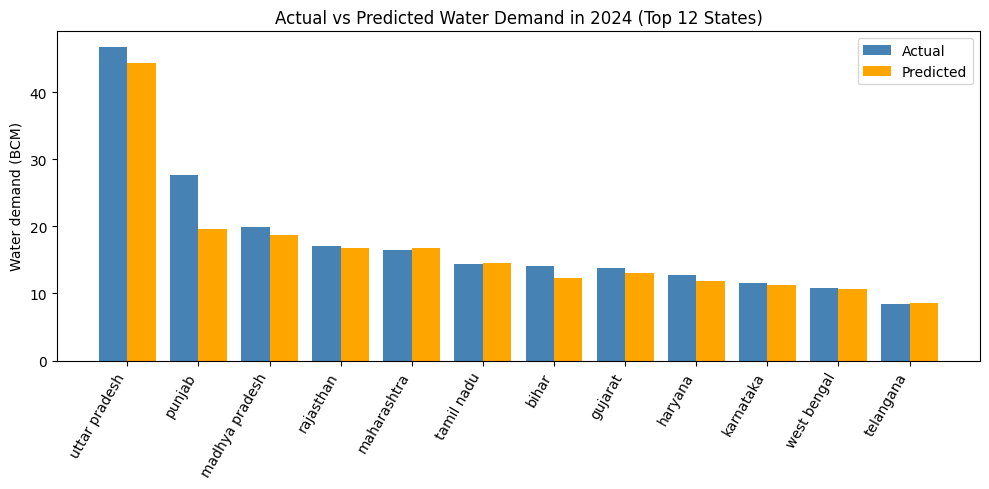

In [ ]:
# Graph: actual vs predicted demand for each state in 2024
plot_data = output.sort_values('Actual_Demand_BCM', ascending=False).head(12)   # 12 biggest states

positions = np.arange(len(plot_data))   # x positions of the bars
bar_width = 0.4

plt.figure(figsize=(10, 5))
plt.bar(positions - bar_width / 2, plot_data['Actual_Demand_BCM'], bar_width, label='Actual', color='steelblue')
plt.bar(positions + bar_width / 2, plot_data['Predicted_Demand_BCM'], bar_width, label='Predicted', color='orange')
plt.xticks(positions, plot_data['State'], rotation=60, ha='right')
plt.ylabel('Water demand (BCM)')
plt.title('Actual vs Predicted Water Demand in 2024 (Top 12 States)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
state_name = 'rajasthan'

state_row = test_rows[test_rows['State'] == state_name]

state_prediction = final_model.predict(state_row[feature_list])

print('State           :', state_name)
print('Actual demand   :', round(state_row['Total_Demand'].values[0], 2), 'BCM')
print('Predicted demand:', round(state_prediction[0], 2), 'BCM')

State           : rajasthan
Actual demand   : 17.05 BCM
Predicted demand: 16.73 BCM


### Plotting Prediction vs Actual Demand for Any State Over Time

Year 2023: Actual = 16.74 BCM | Predicted = 16.74 BCM (Error: -0.00 BCM)
Year 2024: Actual = 17.05 BCM | Predicted = 16.73 BCM (Error: -0.32 BCM)


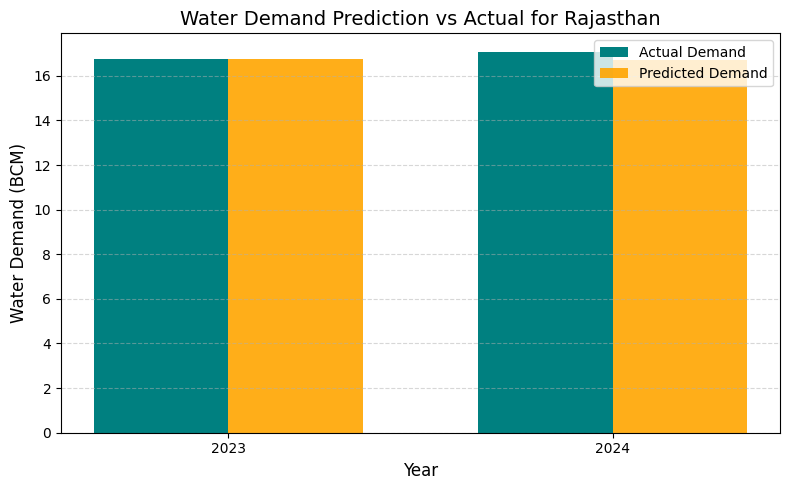

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_state_demand_comparison(state_name):

    state_name_lower = state_name.lower().strip()

    state_data = data[data['State'] == state_name_lower].sort_values('Year')

    if len(state_data) == 0:
        print(f"State '{state_name}' not found. Please double check the spelling!")
        return

    X_state = state_data[feature_list]
    predictions = final_model.predict(X_state)

    years = state_data['Year'].values
    actuals = state_data['Total_Demand'].values


    plt.figure(figsize=(8, 5))
    x_indices = np.arange(len(years))
    bar_width = 0.35

    plt.bar(x_indices - bar_width/2, actuals, bar_width, label='Actual Demand', color='teal')
    plt.bar(x_indices + bar_width/2, predictions, bar_width, label='Predicted Demand', color='orange', alpha=0.9)

    plt.title(f'Water Demand Prediction vs Actual for {state_name.title()}', fontsize=14)
    plt.xlabel('Year', fontsize=12)
    plt.ylabel('Water Demand (BCM)', fontsize=12)
    plt.xticks(x_indices, years)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)


    for i in range(len(years)):
        error = predictions[i] - actuals[i]
        print(f"Year {years[i]}: Actual = {actuals[i]:.2f} BCM | Predicted = {predictions[i]:.2f} BCM (Error: {error:+.2f} BCM)")

    plt.tight_layout()
    plt.show()

plot_state_demand_comparison('Rajasthan')

### Evaluating Regression Performance for Gradient Boosting


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

gb_model = models['Gradient Boosting']
gb_model.fit(X_train_t, y_train_t)
gb_predictions = gb_model.predict(X_test_t)

# 1. R2 Score
r2 = r2_score(y_test_t, gb_predictions)

# 2. Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test_t, gb_predictions)

# 3. Root Mean Squared Error (RMSE)
rmse = np.sqrt(mean_squared_error(y_test_t, gb_predictions))

# 4. Mean Absolute Percentage Error (MAPE)
# We exclude actuals that are exactly 0 to avoid division by zero errors
mask = y_test_t > 0
mape = np.mean(np.abs((y_test_t[mask] - gb_predictions[mask]) / y_test_t[mask])) * 100

print("--- Regression Evaluation Metrics for Gradient Boosting (2024 Test Set) ---")
print(f"R² Score                      : {r2:.4f} (Explains {r2*100:.1f}% of the variance)")
print(f"Mean Absolute Error (MAE)     : {mae:.4f} BCM (Average prediction offset)")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} BCM (Penalizes larger outliers)")
print(f"Mean Absolute % Error (MAPE)  : {mape:.2f}% (Average percentage error on non-zero states)")

--- Regression Evaluation Metrics for Gradient Boosting (2024 Test Set) ---
R² Score                      : 0.9773 (Explains 97.7% of the variance)
Mean Absolute Error (MAE)     : 0.5185 BCM (Average prediction offset)
Root Mean Squared Error (RMSE): 1.4830 BCM (Penalizes larger outliers)
Mean Absolute % Error (MAPE)  : 22.90% (Average percentage error on non-zero states)
